# Toy Regression - Google Colab doğrulaması

Yalnızca bu notebook'u Colab'a yükleyin. **Runtime > Change runtime type > GPU**
(varsa T4) seçip **Runtime > Run all** uygulayın. Drive bağlama, GitHub clone,
başka dosya yükleme veya Windows `.venv` taşıma gerekmez.

Notebook sekiz Python kaynağını ve yerel deneyin sabit 20 noktalı CSV'sini içerir.
02-06 temel deneyleri, 07 üç seed deneyini ve 08 tanı analizini sırayla çalıştırır.
01 veri üretim kaynağı da gömülüdür; aynı deney girdilerini korumak için CSV yeniden
üretilmez. Mevcut mimari, 3000 epoch, learning rate, seed ve M değerleri korunur.

**Bu dosya henüz gerçek Colab üzerinde denenmedi.** Yerel Run All kontrolü tüm
hücreleri eğitim kapalı modda yürütür. Gerçek Colab Run All, modelleri yeni ve
izole bir çalışma alanında eğitir; yerel sonuçları kullanmaz veya üzerine yazmaz.


In [1]:
import os
import sys
import importlib.util
from pathlib import Path

# Must precede torch/CUDA initialization; unchanged deterministic setup for step 07.
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ['MPLBACKEND'] = 'Agg'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
sys.dont_write_bytecode = True
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except (ModuleNotFoundError, ImportError, ValueError):
    IN_COLAB = False
VALIDATION_ONLY = os.environ.get('TOY_COLAB_VALIDATE_ONLY') == '1' or not IN_COLAB
ALLOW_TRAINING = IN_COLAB and not VALIDATION_ONLY
print('Mode:', 'COLAB TRAINING' if ALLOW_TRAINING else 'LOCAL COMPATIBILITY ONLY - NO TRAINING')


Mode: COLAB TRAINING


## Ortam ve bağımlılıklar
Colab'ın hazır CUDA destekli PyTorch paketi korunur. Yalnız eksik NumPy veya
Matplotlib kurulabilir; torch/torchvision, Windows CUDA wheel'i veya eski `.venv`
kurulmaz. GPU yoksa eğitim başlamadan açık hata verilir.


In [2]:
import subprocess
import inspect

missing = []
for module, requirement in [('numpy', 'numpy>=1.26,<3'), ('matplotlib', 'matplotlib>=3.8,<4')]:
    if importlib.util.find_spec(module) is None:
        missing.append(requirement)
if missing:
    if VALIDATION_ONLY:
        raise RuntimeError(f'Local validation dependencies are missing: {missing}')
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)

import torch
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
if 'weights_only' not in inspect.signature(torch.load).parameters:
    raise RuntimeError('Use a clean current Colab runtime with a supported preinstalled PyTorch')
if ALLOW_TRAINING and not torch.cuda.is_available():
    raise RuntimeError('GPU is unavailable. Select Runtime > Change runtime type > GPU, then Run all')
if VALIDATION_ONLY:
    # Defense in depth: an accidental training call must fail, even on a local GPU.
    def _deny_local_optimizer_step(*args, **kwargs):
        raise RuntimeError('Optimizer steps are prohibited in local compatibility validation')
    torch.optim.Adam.step = _deny_local_optimizer_step
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
print('GPU detected:', torch.cuda.is_available(), '| training enabled:', ALLOW_TRAINING)


Python: 3.13.16 | PyTorch: 2.14.1+cu130
NumPy: 2.4.6 | Matplotlib: 3.10.0
GPU detected: True | training enabled: True


## Gömülü kaynakları yeni çalışma alanına aç
Her Run All yeni `/content/toy_regression_colab_runs/run_*` dizini oluşturur.
Hiçbir eski `outputs/` klasörü, checkpoint veya Drive sonucu kopyalanmaz.
Yerel uyumluluk modu işletim sisteminin geçici dizinini kullanır.


In [3]:
import base64
import gzip
import hashlib
import json
import tempfile

PAYLOAD = '...'
EXPECTED_BUNDLE_SHA256 = '5dcbe6f9dae216c64366129e2c5ef335dadf20f73572dbf9391d1b67b9172f78'
bundle_bytes = base64.b64decode(PAYLOAD, validate=True)
if hashlib.sha256(bundle_bytes).hexdigest() != EXPECTED_BUNDLE_SHA256:
    raise AssertionError('Notebook bundle checksum mismatch')
bundle = json.loads(gzip.decompress(bundle_bytes))
if set(bundle['assets']) != set(bundle['sha256']):
    raise AssertionError('Bundle manifest mismatch')
base = Path('/content/toy_regression_colab_runs') if IN_COLAB else Path(tempfile.gettempdir()) / 'toy_regression_colab_runs'
base.mkdir(parents=True, exist_ok=True)
RUN_ROOT = Path(tempfile.mkdtemp(prefix='run_', dir=base)).resolve()
WORK = RUN_ROOT / 'toy_regression'
WORK.mkdir()
for relative, encoded in bundle['assets'].items():
    if relative.startswith('/') or '\\' in relative or ':' in relative or '..' in Path(relative).parts:
        raise ValueError('Unsafe embedded path')
    target = WORK / relative
    if not target.resolve().is_relative_to(WORK):
        raise ValueError('Bundle path escaped sandbox')
    content = base64.b64decode(encoded, validate=True)
    if hashlib.sha256(content).hexdigest() != bundle['sha256'][relative]:
        raise AssertionError(f'Embedded file changed: {relative}')
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)

spec = importlib.util.spec_from_file_location('_toy_colab_runtime', WORK / 'colab_runtime.py')
runtime_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(runtime_module)
run = runtime_module.ColabRun(RUN_ROOT, bundle['sha256'], allow_training=ALLOW_TRAINING)
print('Isolated run:', RUN_ROOT)


Isolated run: /content/toy_regression_colab_runs/run_br453546


In [4]:
preflight = run.preflight()
assert preflight['training_samples'] == 20
assert preflight['scientific_config']['run_seeds'] == [42, 123, 2026]
assert preflight['scientific_config']['epochs'] == 3000


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "numpy": "2.4.6",
  "matplotlib": "3.10.0",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cuda": "13.0",
  "gpu_available": true,
  "gpu": "Tesla T4"
}
Preflight passed: 8 imports; original dataset SHA-256 adab2533701055f77f024b6a94f042b4e3ad7d18479d14d93d9d042e10790235
Mode: colab_training | isolated output: /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs


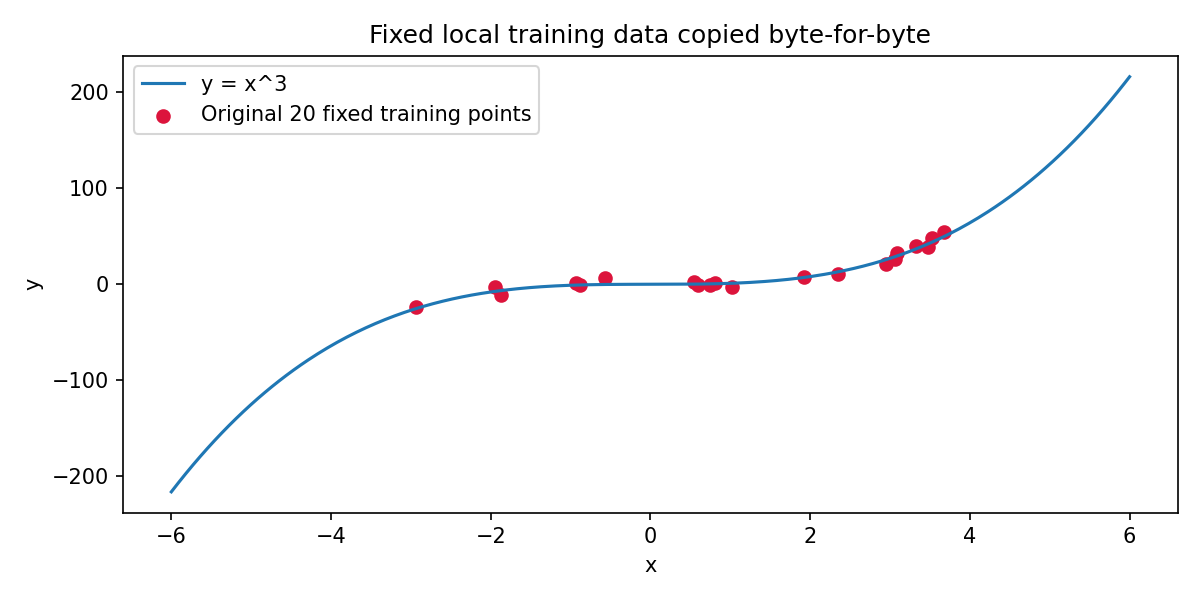

In [5]:
import csv
from IPython.display import display, Image
with (WORK / 'outputs/toy_training_data.csv').open(newline='', encoding='utf-8-sig') as stream:
    samples = list(csv.DictReader(stream))
x = np.array([float(row['x']) for row in samples])
y = np.array([float(row['y']) for row in samples])
grid = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, grid**3, label='y = x^3')
ax.scatter(x, y, c='crimson', label='Original 20 fixed training points')
ax.set(xlabel='x', ylabel='y', title='Fixed local training data copied byte-for-byte')
ax.legend()
fig.tight_layout()
fig.savefig(WORK / 'outputs/toy_dataset_reference.png', dpi=150)
plt.close(fig)
display(Image(filename=str(WORK / 'outputs/toy_dataset_reference.png')))


## 02 - Tek MSE modeli
Kaynak dosya: `02_train_mse.py`. CLI epoch/seed override'ı kullanılmaz.


In [6]:
run.run_step('02_train_mse.py')


Device: cuda
GPU: Tesla T4
Training examples: 20
Network: 1 -> 50 (ReLU) -> 1
Epochs: 3000; learning rate: 0.01; seed: 123
Training ...
Epoch    1/3000 | MSE: 600.7579
Epoch  500/3000 | MSE: 12.6341
Epoch 1000/3000 | MSE: 8.2737
Epoch 1500/3000 | MSE: 8.1170
Epoch 2000/3000 | MSE: 8.0084
Epoch 2500/3000 | MSE: 7.9310
Epoch 3000/3000 | MSE: 7.8748
Final training RMSE: 2.8062 (on the same 20 training points)
Files saved:
  /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/mse_single_model.pt
  /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/mse_single_prediction.png
  /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/mse_single_loss.png
  /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/mse_single_training_log.csv


{'script': '02_train_mse.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/02_train_mse.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 14.960912688999997,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/02_train_mse.py.log'}

## 03 - Beş üyeli MSE ensemble
Kaynak dosya: `03_train_mse_ensemble.py`. CLI epoch/seed override'ı kullanılmaz.


In [7]:
run.run_step('03_train_mse_ensemble.py')


Device: cuda
GPU: Tesla T4
Dataset: 20 samples (same CSV as Steps 1-2)
Network: 1 -> 50 (ReLU) -> 1
Ensemble: 5 independent models, seeds=(123, 124, 125, 126, 127)
Epochs: 3000; LR: 0.01

=== Model 1/5 | seed=123 ===
  Epoch    1/3000 | MSE: 600.7579
  Epoch  500/3000 | MSE: 12.6341
  Epoch 1000/3000 | MSE: 8.2737
  Epoch 1500/3000 | MSE: 8.1170
  Epoch 2000/3000 | MSE: 8.0084
  Epoch 2500/3000 | MSE: 7.9310
  Epoch 3000/3000 | MSE: 7.8748
  Final training RMSE: 2.8062

=== Model 2/5 | seed=124 ===
  Epoch    1/3000 | MSE: 570.2838
  Epoch  500/3000 | MSE: 19.9783
  Epoch 1000/3000 | MSE: 10.3225
  Epoch 1500/3000 | MSE: 8.2055
  Epoch 2000/3000 | MSE: 7.1548
  Epoch 2500/3000 | MSE: 6.3790
  Epoch 3000/3000 | MSE: 6.1713
  Final training RMSE: 2.4842

=== Model 3/5 | seed=125 ===
  Epoch    1/3000 | MSE: 553.3436
  Epoch  500/3000 | MSE: 14.5941
  Epoch 1000/3000 | MSE: 8.1939
  Epoch 1500/3000 | MSE: 6.4620
  Epoch 2000/3000 | MSE: 6.2541
  Epoch 2500/3000 | MSE: 6.1265
  Epoch 3000/

{'script': '03_train_mse_ensemble.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/03_train_mse_ensemble.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 28.146048645999997,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/03_train_mse_ensemble.py.log'}

## 04 - Tek Gaussian NLL modeli
Kaynak dosya: `04_train_gaussian_nll.py`. CLI epoch/seed override'ı kullanılmaz.


In [8]:
run.run_step('04_train_gaussian_nll.py')


Device: cuda
GPU: Tesla T4
Dataset: 20 training examples (same CSV as previous steps)
Network: 1 -> 50 (ReLU) -> 2 (mean + variance)
Epochs: 3000; learning rate: 0.001; seed: 123
y normalization: mean=12.5198, std=20.4321 (train only)
Epoch    1/3000 | train Gaussian NLL: 5.2349
Epoch  500/3000 | train Gaussian NLL: 2.3527
Epoch 1000/3000 | train Gaussian NLL: 2.1709
Epoch 1500/3000 | train Gaussian NLL: 2.1236
Epoch 2000/3000 | train Gaussian NLL: 2.0703
Epoch 2500/3000 | train Gaussian NLL: 2.0144
Epoch 3000/3000 | train Gaussian NLL: 1.9576

=== RESULTS (20 TRAINING POINTS; NOT HELD-OUT TEST SCORES) ===
Train RMSE: 2.3212
Train Gaussian NLL (original y units): 1.9576

x       true y      pred mean      pred std      in mean +/- 3 std?
-6     -216.00        -75.70           0.02          False
-4      -64.00        -41.55           0.06          False
+0       +0.00         +3.96           1.24          False
+4      +64.00        +65.50           6.46          True
+6     +216.00   

{'script': '04_train_gaussian_nll.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/04_train_gaussian_nll.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 15.616301819,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/04_train_gaussian_nll.py.log'}

## 05 - Gaussian NLL + adversarial training
Kaynak dosya: `05_train_gaussian_nll_at.py`. CLI epoch/seed override'ı kullanılmaz.


In [9]:
run.run_step('05_train_gaussian_nll_at.py')


Device: cuda
GPU: Tesla T4
Step 5: Gaussian NLL + FGSM adversarial training (1 network)
Dataset: 20 training points (same CSV)
Network: 1 -> 50 (ReLU) -> 2 (mean + variance)
Epochs: 3000 | Adam lr: 0.001 | seed: 123
FGSM epsilon = 0.01 * (max x - min x) = 0.066090
Training objective: NLL(clean) + NLL(FGSM), each in normalized units
No clipping of adversarial x; same target y.
Epoch    1/3000 | clean training NLL: 5.2349
Epoch  500/3000 | clean training NLL: 2.4557
Epoch 1000/3000 | clean training NLL: 2.2517
Epoch 1500/3000 | clean training NLL: 2.1936
Epoch 2000/3000 | clean training NLL: 2.1530
Epoch 2500/3000 | clean training NLL: 2.1145
Epoch 3000/3000 | clean training NLL: 2.0850

=== TRAIN METRICS (same 20 points, NOT a test set) ===
Train RMSE: 2.3515
Train Gaussian NLL (original units): 2.0850

x      true y     pred mean    pred std    true in +/-3sigma?
-6    -216.00      -75.86        0.05   False
-4     -64.00      -41.62        0.41   False
+0      +0.00       +4.05       

{'script': '05_train_gaussian_nll_at.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/05_train_gaussian_nll_at.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 23.483935670999983,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/05_train_gaussian_nll_at.py.log'}

## 06 - Beş üyeli Gaussian deep ensemble
Kaynak dosya: `06_train_deep_ensemble.py`. CLI epoch/seed override'ı kullanılmaz.


In [10]:
run.run_step('06_train_deep_ensemble.py')


=== Deep Ensemble: 5 Gaussian NLL networks, NO adversarial training ===
Device: cuda
GPU: Tesla T4
Training points: 20 (same CSV as earlier steps)
Architecture: 1 -> 50 ReLU -> 2 (mu, variance)
Seeds: (123, 124, 125, 126, 127) | Epochs/member: 3000 | Adam lr=0.001
Training y mean=12.5198 / std=20.4321

Training member 1/5 | seed=123
  Epoch    1/3000 | clean train NLL: 5.2349
  Epoch  500/3000 | clean train NLL: 2.3527
  Epoch 1000/3000 | clean train NLL: 2.1709
  Epoch 1500/3000 | clean train NLL: 2.1236
  Epoch 2000/3000 | clean train NLL: 2.0703
  Epoch 2500/3000 | clean train NLL: 2.0144
  Epoch 3000/3000 | clean train NLL: 1.9576
  Final member train RMSE=2.3212 | Gaussian NLL=1.9576

Training member 2/5 | seed=124
  Epoch    1/3000 | clean train NLL: 4.7985
  Epoch  500/3000 | clean train NLL: 2.3846
  Epoch 1000/3000 | clean train NLL: 2.1413
  Epoch 1500/3000 | clean train NLL: 2.0933
  Epoch 2000/3000 | clean train NLL: 2.0256
  Epoch 2500/3000 | clean train NLL: 1.9511
  Epoc

{'script': '06_train_deep_ensemble.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/06_train_deep_ensemble.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 42.908549189999974,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/06_train_deep_ensemble.py.log'}

## 07 - Üç bağımsız seed: 42, 123, 2026
Kaynak dosya: `07_multi_seed_experiments.py`. CLI epoch/seed override'ı kullanılmaz.


In [11]:
run.run_step('07_multi_seed_experiments.py')


=== CMP4509 Toy Regression | Step 07: Multi-Seed ===
Device: cuda (Tesla T4)
Run seeds: [42, 123, 2026]; epochs/model: 3000; models/run: 12
Data: 20 FIXED points | FGSM epsilon=0.066090 | output=/content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/07_seed_experiments

======== RUN 1/3 seed=42 ========

  --- MSE Ensemble (5) ---
    Model 1 | epoch    1/3000 | clean loss 559.40399
    Model 1 | epoch  500/3000 | clean loss 12.50038
    Model 1 | epoch 1000/3000 | clean loss 7.82153
    Model 1 | epoch 1500/3000 | clean loss 6.26651
    Model 1 | epoch 2000/3000 | clean loss 6.14138
    Model 1 | epoch 2500/3000 | clean loss 5.97943
    Model 1 | epoch 3000/3000 | clean loss 5.85314
    Model 2 | epoch    1/3000 | clean loss 579.03009
    Model 2 | epoch  500/3000 | clean loss 12.61096
    Model 2 | epoch 1000/3000 | clean loss 6.70441
    Model 2 | epoch 1500/3000 | clean loss 6.20826
    Model 2 | epoch 2000/3000 | clean loss 6.16480
    Model 2 | epoch 2500/3000 | c

{'script': '07_multi_seed_experiments.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/07_multi_seed_experiments.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 203.21166576899998,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/07_multi_seed_experiments.py.log'}

## 08 - Eğitimsiz belirsizlik tanısı
Kaynak dosya: `08_diagnose_uncertainty.py`. CLI epoch/seed override'ı kullanılmaz.


In [12]:
run.run_step('08_diagnose_uncertainty.py')



=== Step 08 — left OOD diagnosis ===
Run seeds: [42, 123, 2026]
Training target scale: 20.432127
Theoretical minimum predicted Gaussian std: 0.020432
Observed left-OOD Gaussian NLL std (avg runs): 0.020539
Share within 1% of min std: 88.6%
Left-OOD mean absolute error vs noiseless x^3: 71.397
Saved 3 figures + diagnostic table in: /content/toy_regression_colab_runs/run_br453546/toy_regression/outputs/08_uncertainty_diagnostics
NOTE: clean_curve_coverage_95 is NOT coverage on noisy observations.
Use Step 07 aggregate coverage95 for noisy-test coverage in the report.


{'script': '08_diagnose_uncertainty.py',
 'command': ['/usr/bin/python3',
  '-B',
  '-u',
  '/content/toy_regression_colab_runs/run_br453546/toy_regression/08_diagnose_uncertainty.py'],
 'cwd': '/content/toy_regression_colab_runs/run_br453546/toy_regression',
 'status': 'completed',
 'seconds': 3.755682057000058,
 'log': '/content/toy_regression_colab_runs/run_br453546/logs/08_diagnose_uncertainty.py.log'}

## Çıktı doğrulama ve arşiv
Gerçek Colab koşusunda 49 model dosyası (13 temel model + üç seed'de 36 model),
48 seed/bölge metrik satırı ve 16 bölge özeti beklenir. Hata olursa Run All durur;
eksik eğitim sonuçları tamamlanmış gibi gösterilmez.


In [13]:
ARCHIVE = run.finish()
print('Real Colab training completed:', run.report['real_colab_training_completed'])
print('Manifest:', RUN_ROOT / 'run_manifest.json')


Finished: colab_training_complete
Archive: /content/toy_regression_colab_runs/run_br453546/toy_regression_colab_run_br453546.zip
Real Colab training completed: True
Manifest: /content/toy_regression_colab_runs/run_br453546/run_manifest.json


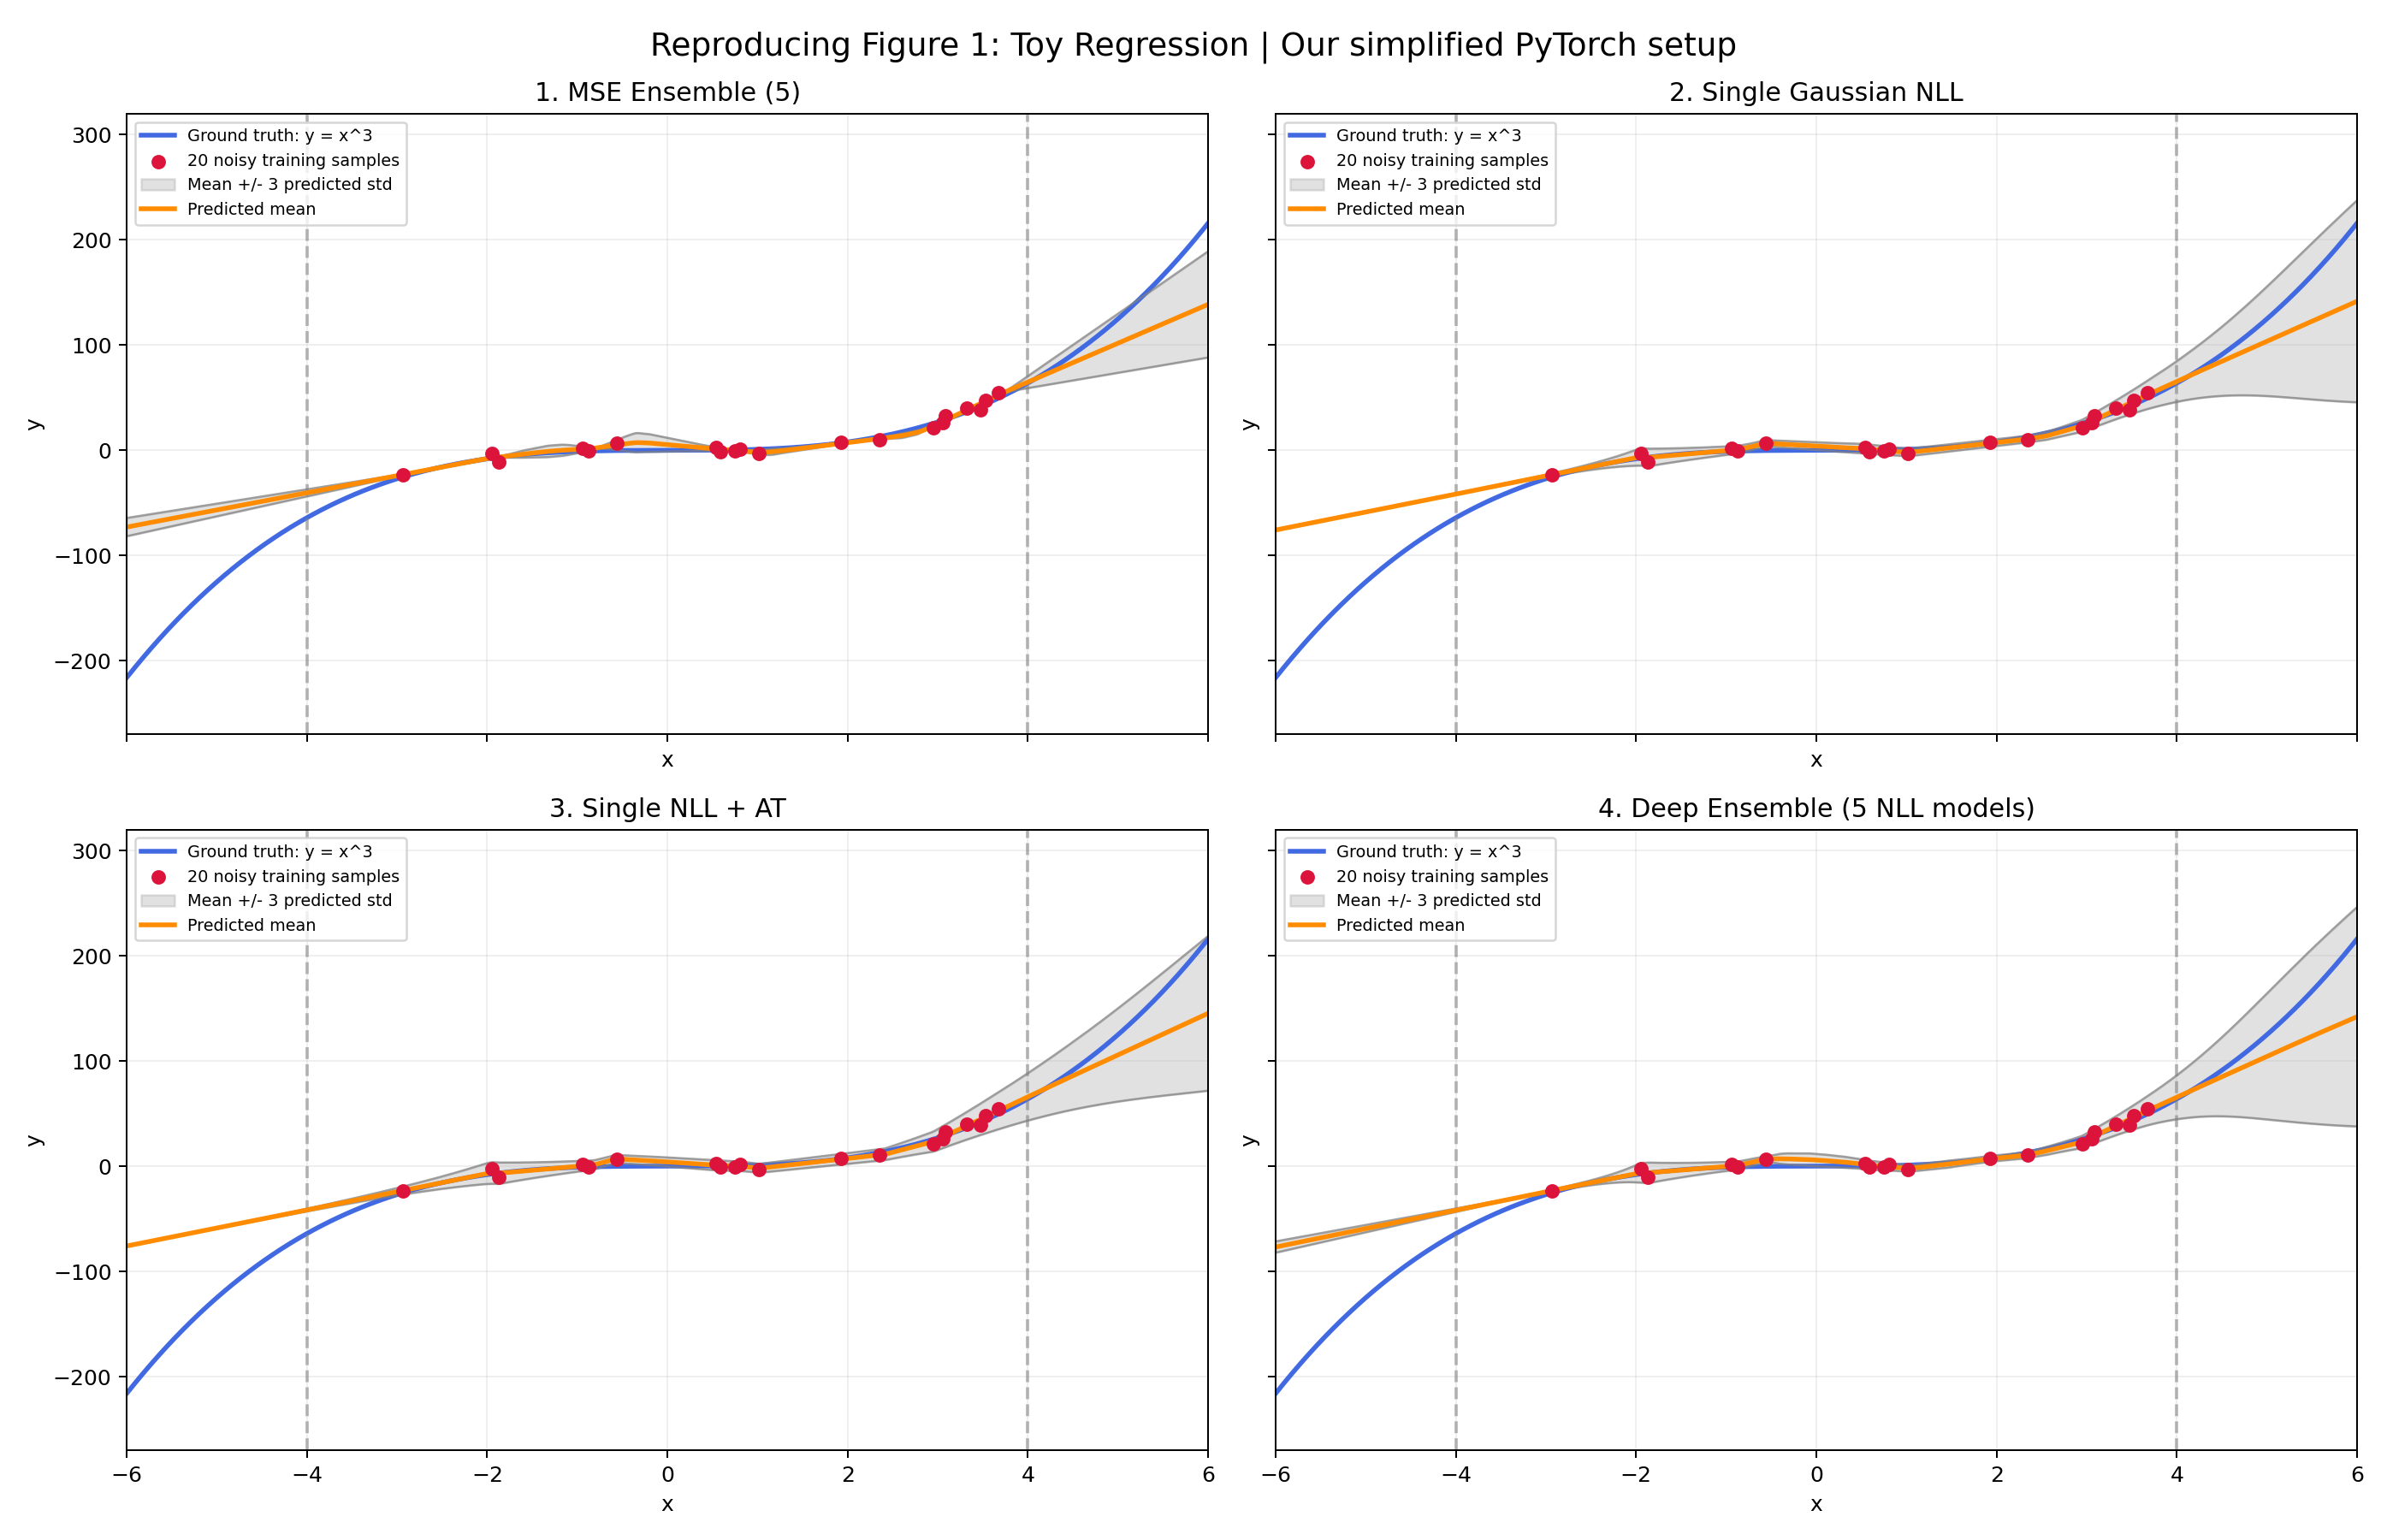

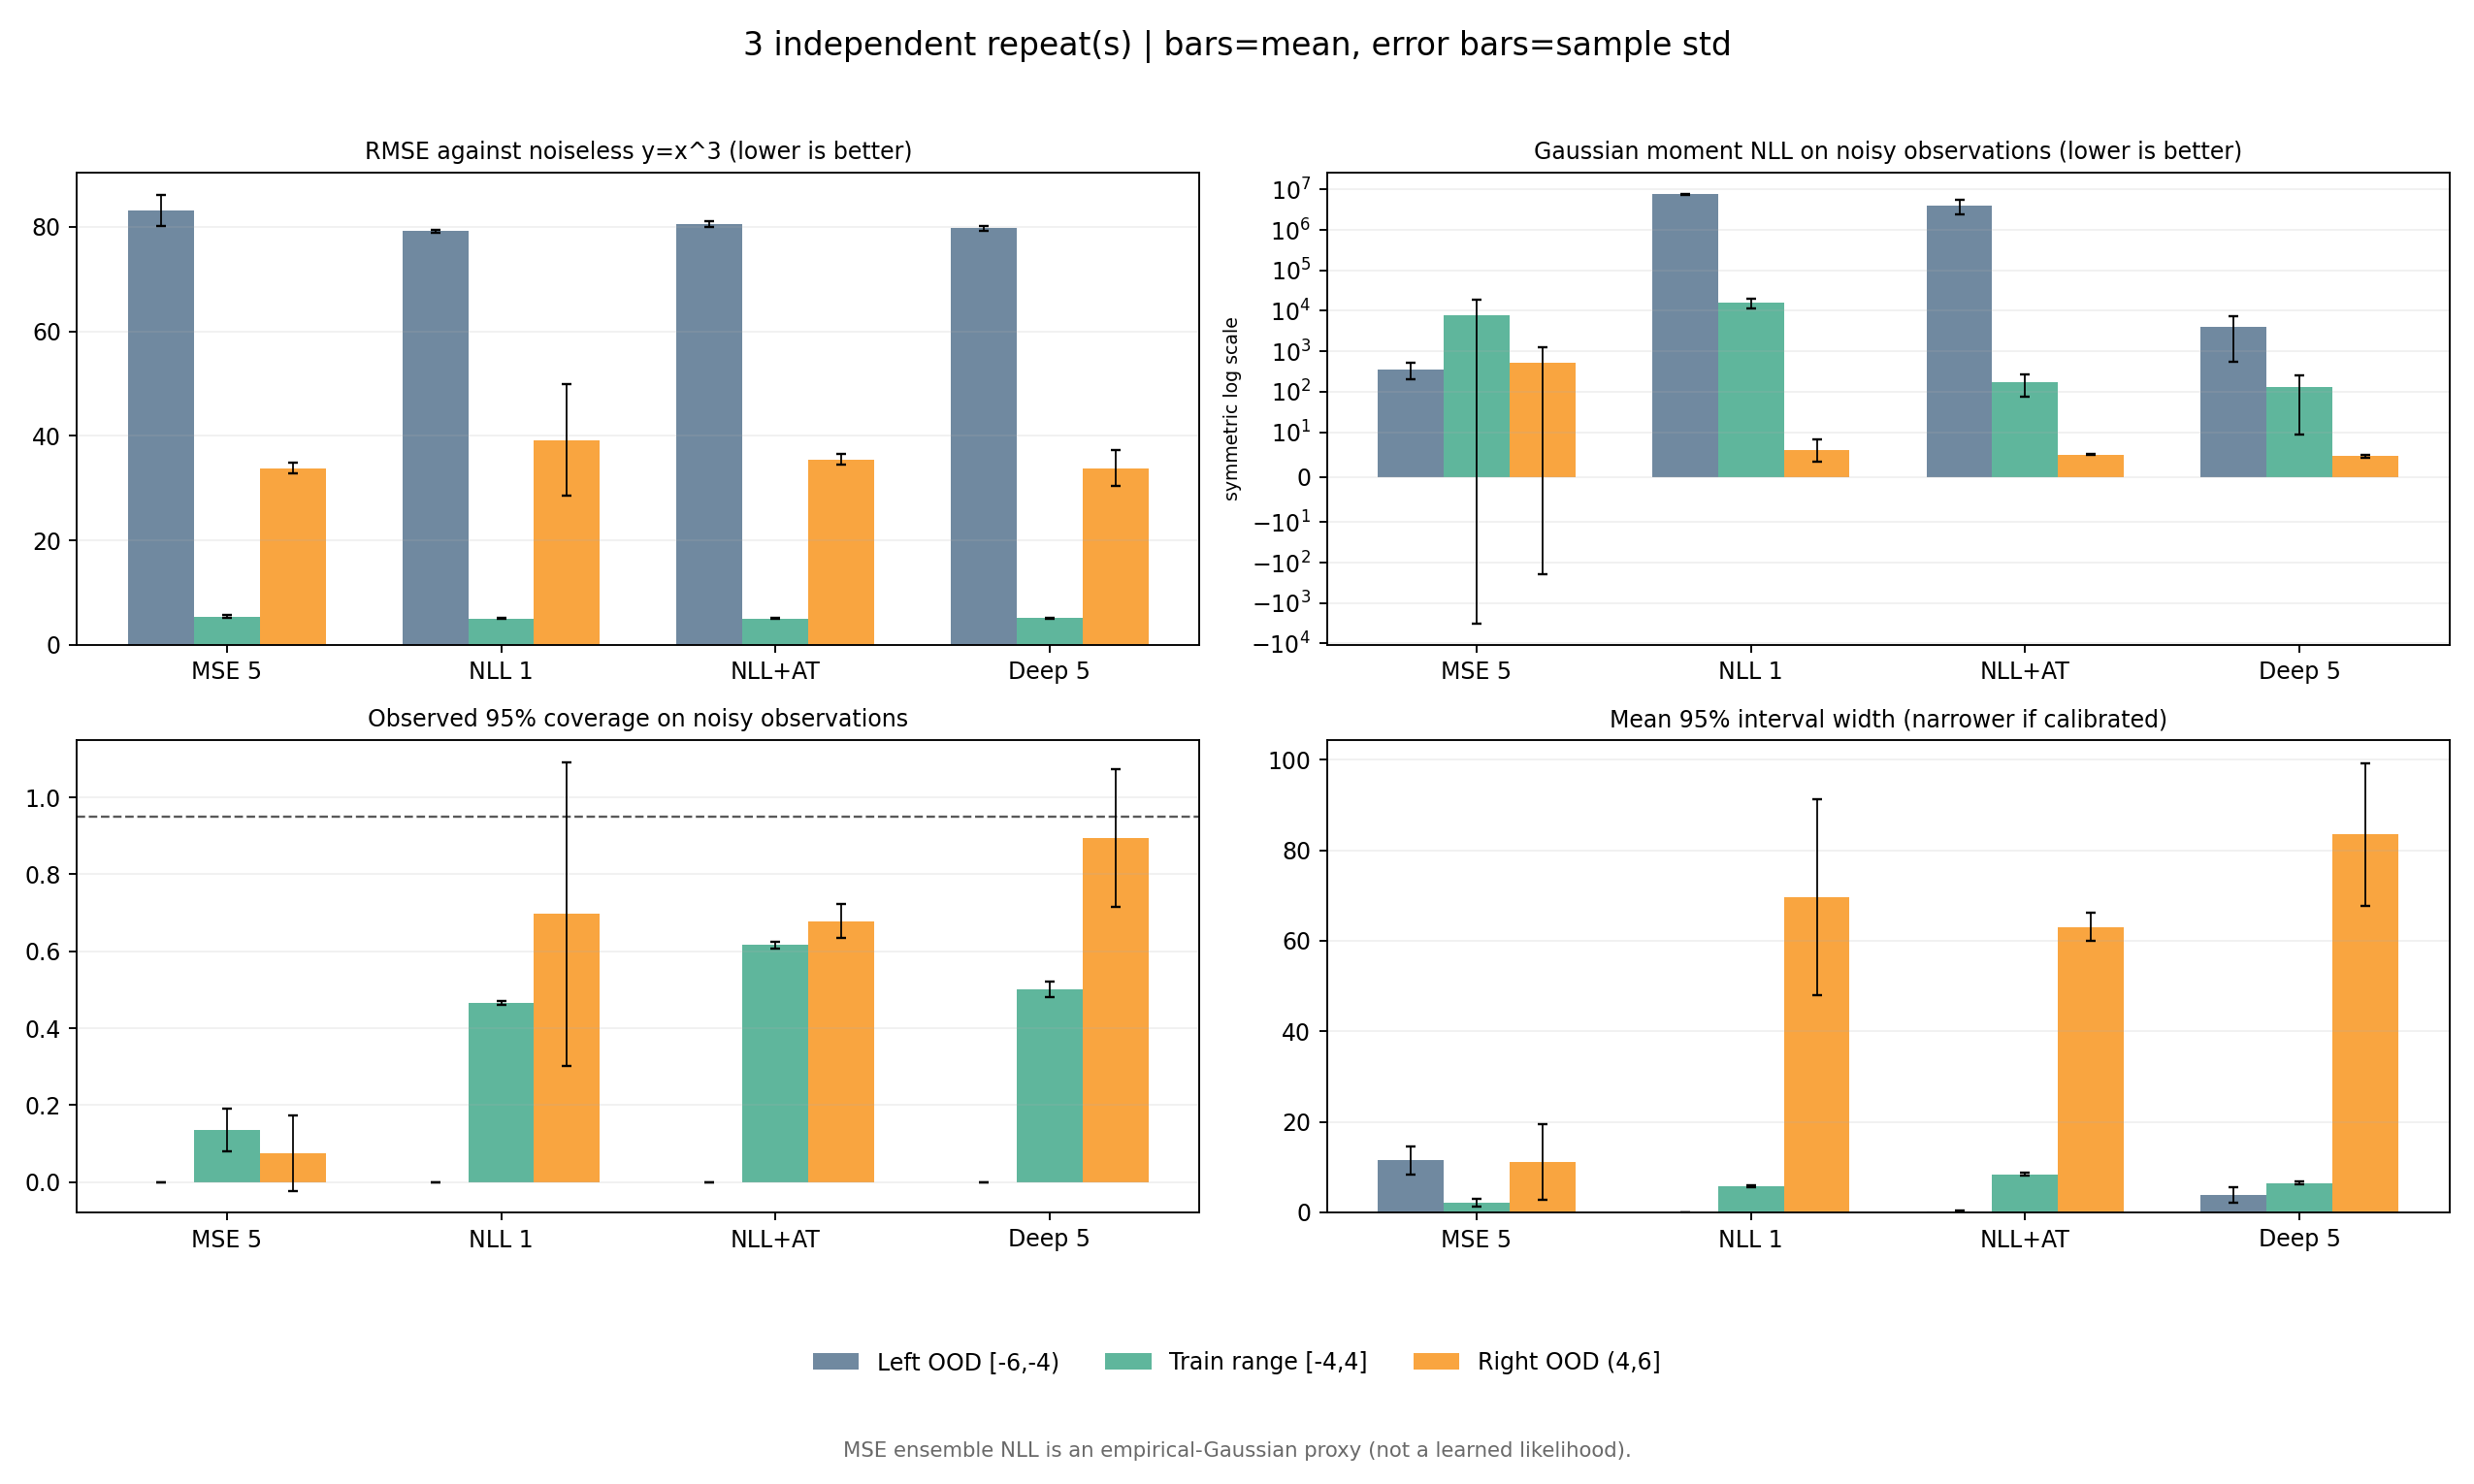

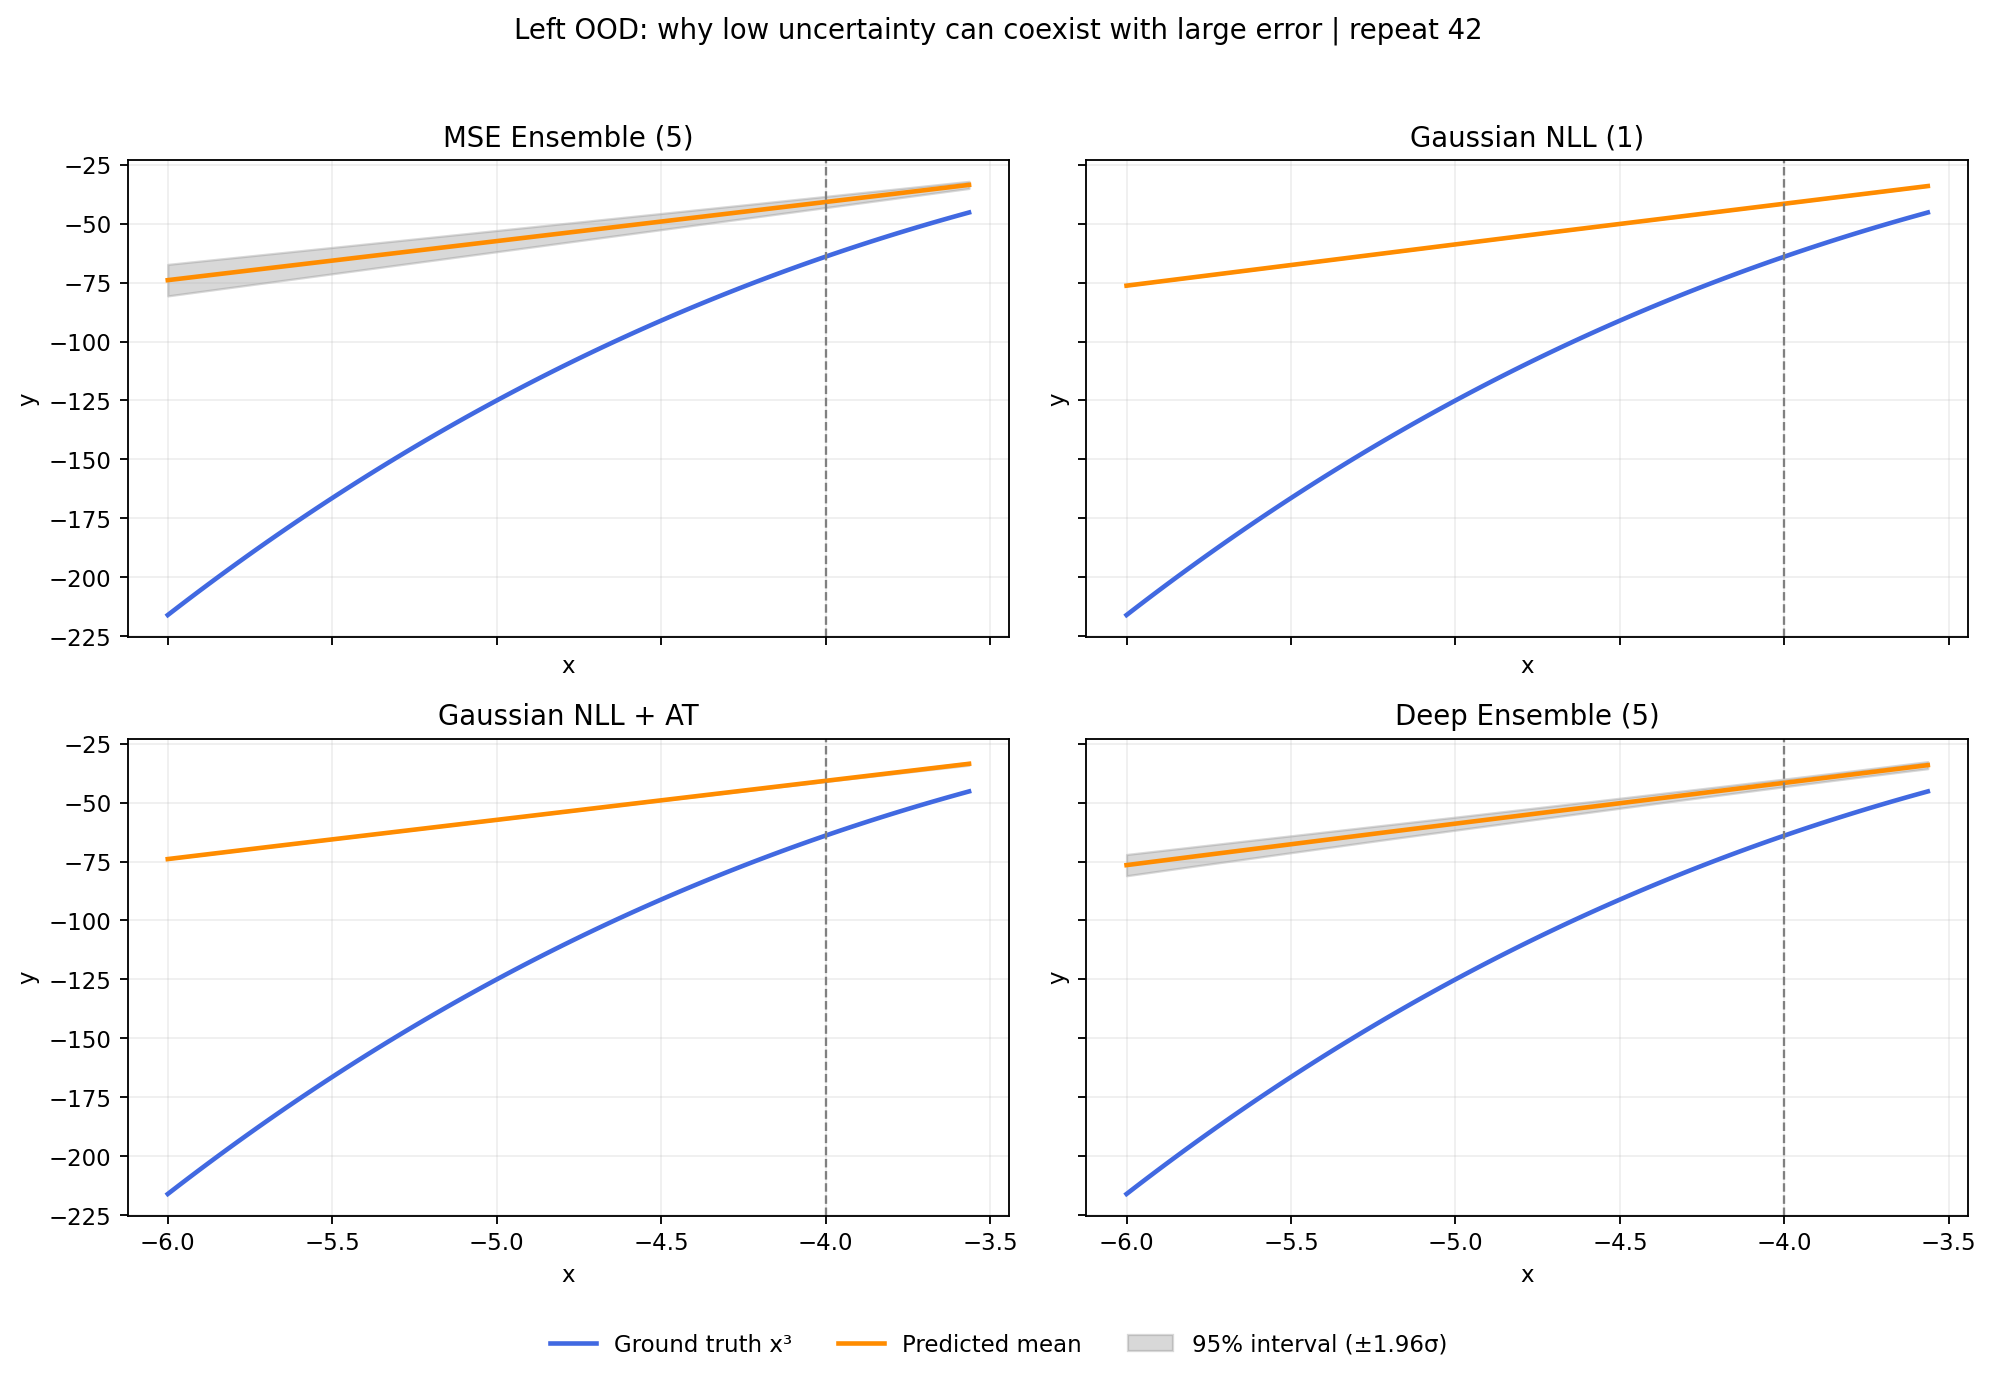

{'method': 'mse_ensemble', 'region': 'left_ood', 'n_runs': '3', 'rmse_clean_mean': '83.13322352988433', 'rmse_clean_sd': '2.895306952357001', 'rmse_noisy_mean': '83.26940997877864', 'rmse_noisy_sd': '2.892857348239488', 'nll_moment_mean': '355.0521214495848', 'nll_moment_sd': '155.84626247285658', 'coverage95_mean': '0.0', 'coverage95_sd': '0.0', 'width95_mean': '11.462674933965275', 'width95_sd': '3.147162247424141', 'avg_aleatoric_std_mean': '0.0', 'avg_aleatoric_std_sd': '0.0', 'avg_epistemic_std_mean': '2.924205501831001', 'avg_epistemic_std_sd': '0.8028622648805167', 'nll_exact_mixture_mean': '', 'nll_exact_mixture_sd': ''}
{'method': 'mse_ensemble', 'region': 'in_distribution', 'n_runs': '3', 'rmse_clean_mean': '5.420518160966146', 'rmse_clean_sd': '0.36023897588500725', 'rmse_noisy_mean': '6.194375949397419', 'rmse_noisy_sd': '0.3173915262242508', 'nll_moment_mean': '7784.984528442569', 'nll_moment_sd': '10950.285793315843', 'coverage95_mean': '0.13577694235588975', 'coverage95_

In [14]:
if ALLOW_TRAINING:
    for relative in [
        'toy_figure1_all_4_panels.png',
        '07_seed_experiments/aggregate/figures/summary_metrics.png',
        '08_uncertainty_diagnostics/figures/left_ood_intervals.png',
    ]:
        display(Image(filename=str(WORK / 'outputs' / relative)))
    with (WORK / 'outputs/07_seed_experiments/aggregate/metrics/summary_mean_sd.csv').open(newline='', encoding='utf-8') as stream:
        for row in csv.DictReader(stream):
            print(row)
else:
    print('Training figures and scores are intentionally unavailable in local validation')


In [15]:
if ALLOW_TRAINING:
    from google.colab import files
    files.download(str(ARCHIVE))
else:
    print('No Colab download: local archive contains setup/validation only, not trained results')
print('Colab files are temporary. Keep the downloaded ZIP and save this executed notebook.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab files are temporary. Keep the downloaded ZIP and save this executed notebook.
